# 💳 Credit Card Customer Segmentation
### K-Means Clustering | Unsupervised Machine Learning

**Project question:** Can we discover meaningful customer groups from their credit-card activity?

**Project objective:** Group credit card customers with similar payment and shopping behavior.

**Problem type:** Clustering — there is no target column (`y`) to predict.

**Dataset:** `CC GENERAL.csv` (8,950 customers, 18 columns)

**Source:** [Credit Card Dataset for Clustering on Kaggle](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata)

> In this project, we will group credit card customers based on their spending, cash advances, and payment habits. Then, we will analyze the characteristics of each group

## 📖 Data Dictionary

| Column | Meaning |
|---|---|
| `CUST_ID` | Customer identifier |
| `BALANCE` | Credit card balance |
| `BALANCE_FREQUENCY` | Frequency of recorded balance (0–1) |
| `PURCHASES` | Total purchase amount |
| `ONEOFF_PURCHASES` | Total one-off purchase amount |
| `INSTALLMENTS_PURCHASES` | Total installment purchase amount |
| `CASH_ADVANCE` | Total cash advance amount |
| `PURCHASES_FREQUENCY` | Purchase frequency (0–1) |
| `ONEOFF_PURCHASES_FREQUENCY` | One-off purchase frequency (0–1) |
| `PURCHASES_INSTALLMENTS_FREQUENCY` | Installment purchase frequency (0–1) |
| `CASH_ADVANCE_FREQUENCY` | Cash advance frequency (mostly 0–1; some values exceed 1) |
| `CASH_ADVANCE_TRX` | Number of cash advance transactions |
| `PURCHASES_TRX` | Number of purchase transactions |
| `CREDIT_LIMIT` | Credit limit |
| `PAYMENTS` | Total payments |
| `MINIMUM_PAYMENTS` | Minimum payment amounts |
| `PRC_FULL_PAYMENT` | Proportion of full payments (0–1) |
| `TENURE` | Length of observation in months |


## 1. Import Libraries
We use Pandas for data, Matplotlib and Seaborn for charts

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Data
Load `CC GENERAL.csv` with Pandas into `df` and display the first five rows

In [2]:
df = pd.read_csv('CC GENERAL.csv')
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 3. Exploratory Data Analysis (EDA)
First, check the size, column types, missing values, and numerical values

In [3]:
df.shape

(8950, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [5]:
df.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [6]:
df.describe().round(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8949.00,8950.00,8637.00,8950.00,8950.00
mean,1564.47,0.88,1003.20,592.44,411.07,978.87,0.49,0.20,0.36,0.14,3.25,14.71,4494.45,1733.14,864.21,0.15,11.52
std,2081.53,0.24,2136.63,1659.89,904.34,2097.16,0.40,0.30,0.40,0.20,6.82,24.86,3638.82,2895.06,2372.45,0.29,1.34
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,50.00,0.00,0.02,0.00,6.00
25%,128.28,0.89,39.64,0.00,0.00,0.00,0.08,0.00,0.00,0.00,0.00,1.00,1600.00,383.28,169.12,0.00,12.00
50%,873.39,1.00,361.28,38.00,89.00,0.00,0.50,0.08,0.17,0.00,0.00,7.00,3000.00,856.90,312.34,0.00,12.00
75%,2054.14,1.00,1110.13,577.40,468.64,1113.82,0.92,0.30,0.75,0.22,4.00,17.00,6500.00,1901.13,825.49,0.14,12.00
max,19043.14,1.00,49039.57,40761.25,22500.00,47137.21,1.00,1.00,1.00,1.50,123.00,358.00,30000.00,50721.48,76406.21,1.00,12.00


### Data Visualization
Purchase frequency ranges from 0 to 1. Let's see how often customers use their credit cards for purchases

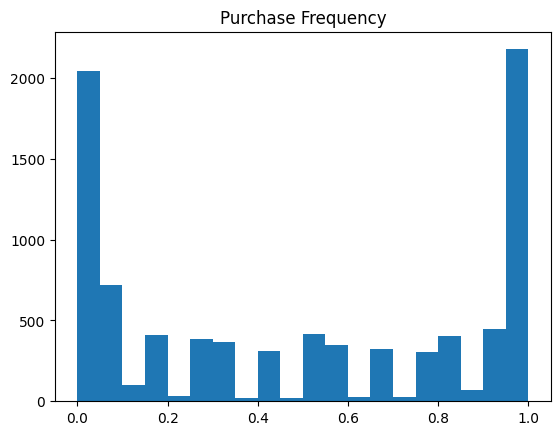

In [7]:
plt.hist(df['PURCHASES_FREQUENCY'], bins=20)
plt.title('Purchase Frequency')
plt.show()

## 4. Select Features (x)
We select four features to analyze customer behavior. `CUST_ID` is excluded because it is only an identifier. The selected features have no missing values.

In [8]:
x = df[['PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
        'PRC_FULL_PAYMENT', 'BALANCE_FREQUENCY']]
x.isnull().sum()

PURCHASES_FREQUENCY       0
CASH_ADVANCE_FREQUENCY    0
PRC_FULL_PAYMENT          0
BALANCE_FREQUENCY         0
dtype: int64

## 5. Scale the Data
K-Means groups customers based on distances between data points. We use `StandardScaler` to standardize the four features so they can be compared on a similar scale.

In [9]:
from sklearn.preprocessing import StandardScaler
x_scaled = StandardScaler().fit_transform(x)

## 6. K-Means: Compare Cluster Counts
K-Means groups similar customers. We compare cluster counts from **2 to 8**

- **WCSS (Elbow):** Lower means points are closer to their cluster centers; WCSS naturally decreases as the number of clusters increases
- **Silhouette Score:** Higher generally means better separation. We use a fixed sample of 1,200 customers to keep the calculation fast

Silhouette Score is **not an accuracy score**

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
scores = []

for i in range(2, 9):
    model = KMeans(i, random_state=42, n_init=10)
    model.fit(x_scaled)
    labels = model.predict(x_scaled)
    wcss.append(model.inertia_)
    scores.append(silhouette_score(x_scaled, labels, sample_size=1200, random_state=42))

### Elbow Graph
Look for the point where improvements start to slow down.

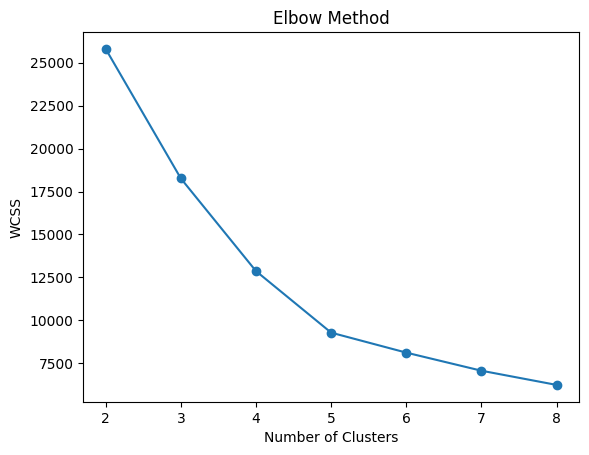

In [11]:
plt.plot(range(2, 9), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

### Silhouette Score Comparison
Higher scores are generally better. The highest score is not automatically the best business choice

In [12]:
pd.DataFrame({'Clusters': range(2, 9), 'Silhouette Score': scores}).round(3)

,Clusters,Silhouette Score
0,2,0.318
1,3,0.381
2,4,0.421
3,5,0.442
4,6,0.435
5,7,0.447
6,8,0.430


## 7. Final K-Means Model
We choose **5 clusters** as a practical balance between clear customer groups and model simplicity. In this dataset, 7 clusters have a slightly higher sampled Silhouette Score, but 5 clusters are easier to interpret.

`random_state=42` makes the result reproducible. `n_init=10` runs K-Means from several starting points.

**Important:** The `Cluster` column is added to `df`, **not** to the training features `x`

In [13]:
model = KMeans(5, random_state=42, n_init=10)
model.fit(x_scaled)
labels = model.predict(x_scaled)
df['Cluster'] = labels

df[['CUST_ID', 'Cluster']].head()

,CUST_ID,Cluster
0,C10001,4
1,C10002,4
2,C10003,0
3,C10004,1
4,C10005,4


In [14]:
print('Silhouette Score:', round(silhouette_score(x_scaled, labels, sample_size=1200, random_state=42), 3))

Silhouette Score: 0.442


## 8. Visualize the Clusters
First, we visualize the number of customers in each cluster. Then, we use a scatter plot to compare purchase frequency and cash advance frequency across the customer groups

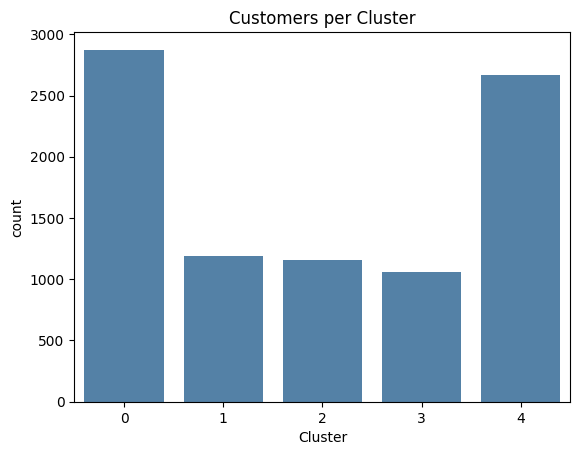

In [15]:
sns.countplot(data=df, x='Cluster', color='steelblue')
plt.title('Customers per Cluster')
plt.show()

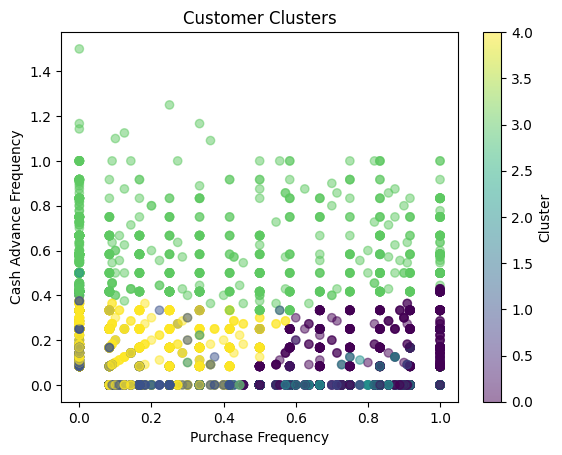

In [16]:
plt.scatter(df['PURCHASES_FREQUENCY'], df['CASH_ADVANCE_FREQUENCY'], c=labels, alpha=0.5)
plt.xlabel('Purchase Frequency')
plt.ylabel('Cash Advance Frequency')
plt.title('Customer Clusters')
plt.colorbar(label='Cluster')
plt.show()

## 9. Customer Segment Analysis
To understand the clusters, compare the **average behavior frequencies** and **median financial amounts**.

Cluster IDs (0, 1, 2, ...) are only labels. They do not indicate ranking, risk, or creditworthiness.

In [17]:
df.groupby('Cluster')[['PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
                       'PRC_FULL_PAYMENT', 'BALANCE_FREQUENCY']].mean().round(2)

,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT,BALANCE_FREQUENCY
Cluster,,,,
0,0.86,0.06,0.06,0.98
1,0.26,0.05,0.14,0.35
2,0.83,0.01,0.82,0.89
3,0.30,0.58,0.04,0.97
4,0.12,0.14,0.02,0.96


In [18]:
df.groupby('Cluster')[['BALANCE', 'PURCHASES', 'CREDIT_LIMIT', 'PAYMENTS']].median().round(0)

,BALANCE,PURCHASES,CREDIT_LIMIT,PAYMENTS
Cluster,,,,
0,1037.0,968.0,3500.0,1076.0
1,24.0,135.0,3000.0,372.0
2,91.0,962.0,4000.0,1071.0
3,2865.0,89.0,5000.0,1542.0
4,1308.0,20.0,2900.0,628.0


### Cluster Heatmap
The heatmap shows the average values of the four behavioral features for each cluster. This helps us identify differences between the customer groups

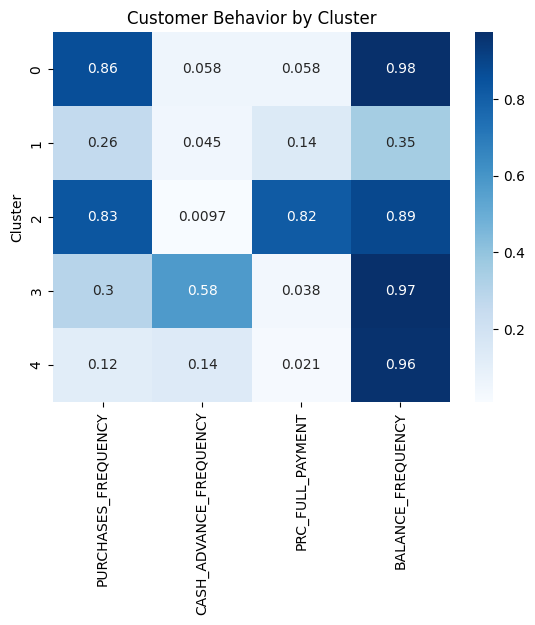

In [19]:
profile = df.groupby('Cluster')[['PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
                                 'PRC_FULL_PAYMENT', 'BALANCE_FREQUENCY']].mean()
sns.heatmap(profile, annot=True, cmap='Blues')
plt.title('Customer Behavior by Cluster')
plt.show()

## 10. Save Results
Save the original dataset with one additional `Cluster` column

In [20]:
df.to_csv('credit_card_segments.csv', index=False)

## ✅ Conclusion

> We grouped 8,950 customers into five segments using K-Means and four behavioral features.

**Illustrative interpretation of the 5 groups:**

| Cluster | Customers | Main observation |
|---|---:|---|
| 0 | 2,874 | Frequent purchases; usually does not pay in full |
| 1 | 1,186 | Infrequent balance activity and relatively low card usage |
| 2 | 1,157 | Frequent purchases and a high full-payment rate |
| 3 | 1,063 | Frequent cash advances and higher balances |
| 4 | 2,670 | Low purchase frequency with ongoing balances |

**Model evaluation:** The 5-cluster solution has a sampled Silhouette Score of approximately **0.442** using the provided dataset. The 7-cluster solution scores slightly higher at approximately **0.447**. Both scores refer to the chosen four scaled features and the specified sampling method; neither proves that the segments are the only correct grouping.

**Business value:** These groups could support further analysis of customer engagement and product usage. Clustering alone is **not** a credit risk model and should not determine credit approvals or eligibility.

**Limitations:** The chosen features and scaling affect cluster results. This is an unsupervised example without ground-truth customer segments or external validation. Real-life use would require further checks.

**References:** [Dataset](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata) · [Original project inspiration](https://thecleverprogrammer.com/2022/10/03/credit-card-clustering-with-machine-learning/)